# Notebook 05 V10 — SMOTE Sensitivity & Stability (CIC-IDS2017)

**Mục tiêu:** Kiểm tra ảnh hưởng của XSS-only SMOTE (600/900/1200 mẫu) so với weighted cross-entropy trên **cùng 3 seeds** và **kiến trúc T4 của V8/V9**. 60 features từ output 03B, 15 classes. Không thay đổi val/test. Model selection theo validation Macro-F1, báo cáo Accuracy, Precision, Recall, F1 từng lớp, confusion matrix, FPR. **Đây là exploratory pilot**, vì test của 03B đã được xem trong V6–V9. Kết quả nghiên cứu cuối cần holdout độc lập.

**Chạy Kaggle:** Add Input *output Notebook 03B*, bật GPU T4; chọn `SEARCH_MODE='balanced'` (3 seeds × 4 settings); `smoke` để kiểm tra trước (1 seed × 2 settings). Khi hoàn tất Save Version để giữ thư mục `nids_outputs/05_V10_SMOTE_Stability`. Không cần output V8/V9.

**Lưu ý khoa học:** SMOTE trên flow có thể tạo các giá trị vật lý không hợp lệ, nhất là port/count/flag. Notebook chỉ *audit*, **không tuyên bố các mẫu tổng hợp là flow thật**. Không dùng validation/test để fit scaler hay tạo synthetic data. Cùng tham số và seed cho mọi điều kiện; SMOTE được fit riêng trên train cho mỗi seed.

## 1. Môi trường và cấu hình

In [39]:
from pathlib import Path
import json, time, random, hashlib, gc, shutil
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import joblib
from IPython.display import display
import matplotlib.pyplot as plt

SEARCH_MODE = 'balanced'  # 'smoke', 'balanced', 'full'
INPUT_DIR = None          # explicit folder containing 03B artifacts if auto-discovery is ambiguous
OUTPUT = Path('/kaggle/working/nids_outputs/05_V10_SMOTE_Stability') if Path('/kaggle/working').exists() else Path('reports/05_V10_SMOTE_Stability')
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED=42
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BUDGET={
 'smoke':   dict(epochs=2, patience=2, seeds=[42], batch=256),
 'balanced':dict(epochs=55,patience=10, seeds=[42,43,44],batch=256),
 'full':    dict(epochs=80,patience=13, seeds=[42,43,44,45,46],batch=256),
}[SEARCH_MODE]
def seed_everything(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
print('DEVICE', DEVICE, 'GPU',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU', 'BUDGET', BUDGET)
# XSS-only oversampling: fixed before examining validation/test.
SMOTE_TARGETS = [600, 900, 1200] if SEARCH_MODE != 'smoke' else [900]
SMOTE_K_NEIGHBORS = 5
SMOTE_LIMIT = 2000


DEVICE cuda GPU Tesla T4 BUDGET {'epochs': 55, 'patience': 10, 'seeds': [42, 43, 44], 'batch': 256}


## 2. Dữ liệu 03B, bảo đảm đồng nhất split/feature

In [40]:
needed=['cic_expanded_splits.parquet','feature_sets.json','experiment_manifest.json']
if INPUT_DIR is not None:
 candidates=[Path(INPUT_DIR)]
else:
 candidates=[]
 local=Path('/kaggle/working/nids_outputs/03B_CIC_Feature_Engineering')
 if local.is_dir():candidates.append(local)
 if Path('/kaggle/input').exists():
  candidates += [f.parent for f in Path('/kaggle/input').rglob(needed[0])]
valid=sorted({str(p.resolve()) for p in candidates if all((p/f).is_file() for f in needed)})
if len(valid)!=1:
 raise FileNotFoundError(f'Expected ONE complete Notebook 03B output; found {valid}. Add Input output 03B or set INPUT_DIR.')
input_dir=Path(valid[0]);split_path=input_dir/needed[0]
manifest=json.loads((input_dir/'experiment_manifest.json').read_text(encoding='utf8'))
feature_sets=json.loads((input_dir/'feature_sets.json').read_text(encoding='utf8'))
feature_variant=manifest['validation_selected_feature_set']
features=list(feature_sets[feature_variant]);N_FEATURES=len(features)
df=pd.read_parquet(split_path)
required={'Label','_binary_label','_split','_source_file','_source_row','_duplicate_group'}
assert required.issubset(df.columns),f'Missing columns: {required-set(df.columns)}'
assert len(df)==int(manifest['sample_rows'])
assert set(df['_split'].astype(str))=={'train','val','test'}
assert len(features)==len(set(features)) and set(features).issubset(df.columns)
assert all(not f.startswith('_') and f!='Label' for f in features)
assert df.groupby('_duplicate_group')['_split'].nunique().max()==1,'Exact duplicate group leaked across splits'
assert not df.duplicated(['_source_file','_source_row']).any(),'Duplicate source row'
labels=df['Label'].astype(str)
assert np.array_equal(df['_binary_label'].astype(int).to_numpy(),labels.ne('BENIGN').astype(int).to_numpy())
mask={p:df['_split'].eq(p).to_numpy() for p in ['train','val','test']}
enc=LabelEncoder().fit(labels.loc[mask['train']])
assert set(enc.classes_)==set(labels),'A class is absent from train'
y={p:enc.transform(labels.loc[m]).astype(np.int64) for p,m in mask.items()}
classes=enc.classes_.tolist();K=len(classes);benign_idx=int(enc.transform(['BENIGN'])[0]);all_ids=np.arange(K)
raw=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).astype('float32')
sha=hashlib.sha256(split_path.read_bytes()).hexdigest()
print('INPUT:',split_path,'SHA256:',sha)
print('FEATURE SET:',feature_variant,'N_FEATURES:',N_FEATURES,'CLASSES:',K)
print('SPLIT:',{p:int(m.sum()) for p,m in mask.items()})
print(pd.crosstab(labels,df['_split']).to_string())
assert N_FEATURES==60 and K==15, 'This experiment expects the same 60-feature/15-class protocol as 04 V2'
(OUTPUT/'feature_names.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf8')

INPUT: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/03B_CIC_Feature_Engineering/cic_expanded_splits.parquet SHA256: d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152
FEATURE SET: with_port N_FEATURES: 60 CLASSES: 15
SPLIT: {'train': 23922, 'val': 7862, 'test': 7409}
_split                        test  train   val
Label                                          
BENIGN                        1353   4279  1368
Bot                            387   1190   389
DDoS                           681   2107   712
DoS GoldenEye                  681   2096   723
DoS Hulk                       585   2136   779
DoS Slowhttptest               627   2186   687
DoS slowloris                  699   2077   724
FTP-Patator                    558   2259   683
Heartbleed                       2      8     1
Infiltration                     8     21     7
PortScan                       717   2102   681
SSH-Patator                    681   2112   707
Web Attack ï¿

1283

## 3. Imputation / Standardization — fit train only

In [41]:
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
scaler=StandardScaler()
train_imp=imputer.fit_transform(raw.loc[mask['train']])
X={'train':scaler.fit_transform(train_imp).astype(np.float32)}
for p in ['val','test']:
 X[p]=scaler.transform(imputer.transform(raw.loc[mask[p]])).astype(np.float32)
for p in X:
 assert X[p].shape==(len(y[p]),N_FEATURES) and np.isfinite(X[p]).all()
train_counts=np.bincount(y['train'],minlength=K)
print('Train count min / max:',train_counts.min(),train_counts.max())
print('No preprocessing fit on val/test.')
joblib.dump({'imputer':imputer,'scaler':scaler,'label_encoder':enc,'features':features,
 'feature_variant':feature_variant,'split_sha256':sha},OUTPUT/'preprocessing.joblib')

Train count min / max: 8 4279
No preprocessing fit on val/test.


['/kaggle/working/nids_outputs/05_V10_SMOTE_Stability/preprocessing.joblib']

## 4. Kiến trúc CNN–SE–MHSA T4 (giữ nguyên V9)

In [42]:
class FeatureTokenizer(nn.Module):
 def __init__(self,n_features,d_model):
  super().__init__()
  self.weight=nn.Parameter(torch.empty(n_features,d_model))
  self.bias=nn.Parameter(torch.empty(n_features,d_model))
  nn.init.normal_(self.weight,mean=0.,std=.02)
  nn.init.normal_(self.bias,mean=0.,std=.02)
 def forward(self,x):
  return x.unsqueeze(-1)*self.weight.unsqueeze(0)+self.bias.unsqueeze(0)

class SEChannels(nn.Module):
 def __init__(self,d_model,reduction=8):
  super().__init__()
  hidden=max(8,d_model//reduction)
  self.net=nn.Sequential(nn.Linear(d_model,hidden),nn.GELU(),nn.Linear(hidden,d_model),nn.Sigmoid())
 def forward(self,z):
  # z: B,F,D ; squeeze over feature-token positions
  return z * self.net(z.mean(dim=1)).unsqueeze(1)

class TokenResBlock(nn.Module):
 def __init__(self,d_model,dropout):
  super().__init__()
  self.norm=nn.LayerNorm(d_model)
  self.net=nn.Sequential(nn.Linear(d_model,2*d_model),nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model))
  self.dropout=nn.Dropout(dropout)
 def forward(self,x):return x+self.dropout(self.net(self.norm(x)))

class TokenizedCNNSEAttention(nn.Module):
 def __init__(self,n_features,n_classes,d_model=64,heads=4,dropout=.15,
              use_cnn=True,use_se=True,use_attn=True,use_raw=False):
  super().__init__()
  assert d_model%heads==0
  self.flags={'use_cnn':use_cnn,'use_se':use_se,'use_attn':use_attn,'use_raw':use_raw}
  self.tokenizer=FeatureTokenizer(n_features,d_model)
  self.norm0=nn.Identity()  # preserve scalar feature magnitude before feature mixing
  if use_cnn:
   self.convs=nn.ModuleList([nn.Conv1d(d_model,d_model,k,padding=k//2) for k in (1,3,5)])
   self.conv_fuse=nn.Sequential(nn.Conv1d(3*d_model,d_model,1),nn.GELU())
   self.norm_cnn=nn.LayerNorm(d_model)
  self.se=SEChannels(d_model) if use_se else nn.Identity()
  if use_attn:
   self.attn_norm=nn.LayerNorm(d_model)
   self.mha=nn.MultiheadAttention(d_model,heads,dropout=dropout,batch_first=True)
   self.attn_dropout=nn.Dropout(dropout)
  self.token_mlp=TokenResBlock(d_model,dropout)
  self.pool_gate=nn.Linear(d_model,1)
  rep_dim=3*d_model
  if use_raw:
   self.raw_mlp=nn.Sequential(nn.Linear(n_features,2*d_model),nn.LayerNorm(2*d_model),nn.GELU(),
                              nn.Dropout(dropout),nn.Linear(2*d_model,d_model),nn.GELU())
   rep_dim+=d_model
  self.classifier=nn.Sequential(nn.LayerNorm(rep_dim),nn.Linear(rep_dim,2*d_model),nn.GELU(),
                                nn.Dropout(dropout),nn.Linear(2*d_model,n_classes))
 def forward(self,x):
  z=self.norm0(self.tokenizer(x))
  if self.flags['use_cnn']:
   q=z.transpose(1,2)
   mixed=self.conv_fuse(torch.cat([conv(q) for conv in self.convs],dim=1)).transpose(1,2)
   z=self.norm_cnn(z+mixed)
  z=self.se(z)
  if self.flags['use_attn']:
   q=self.attn_norm(z)
   z=z+self.attn_dropout(self.mha(q,q,q,need_weights=False)[0])
  z=self.token_mlp(z)
  weights=torch.softmax(self.pool_gate(z).squeeze(-1),dim=1)
  attentive=(z*weights.unsqueeze(-1)).sum(dim=1)
  reps=[attentive,z.mean(dim=1),z.amax(dim=1)]
  if self.flags['use_raw']:reps.append(self.raw_mlp(x))
  return self.classifier(torch.cat(reps,dim=1))

ARCHS={
 'T0_TokenOnly': dict(use_cnn=False,use_se=False,use_attn=False,use_raw=False),
 'T1_TokenCNN': dict(use_cnn=True,use_se=False,use_attn=False,use_raw=False),
 'T2_TokenCNN_SE': dict(use_cnn=True,use_se=True,use_attn=False,use_raw=False),
 'T3_TokenCNN_MHSA': dict(use_cnn=True,use_se=False,use_attn=True,use_raw=False),
 'T4_TokenCNN_SE_MHSA': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=False),
 'T5_TokenCNN_SE_MHSA_Raw': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=True),
}
def make_model(arch,d_model=64,dropout=.15,heads=4):
 return TokenizedCNNSEAttention(N_FEATURES,K,d_model=d_model,dropout=dropout,heads=heads,**ARCHS[arch])
for name in ARCHS:
 m=make_model(name).to(DEVICE)
 xx=torch.randn(3,N_FEATURES,device=DEVICE)
 assert m(xx).shape==(3,K)
 m(xx).sum().backward()
 assert all(p.grad is not None for p in m.parameters() if p.requires_grad)
 print(name,sum(p.numel() for p in m.parameters()),'params; forward/backward OK')
 del m
if DEVICE.type=='cuda':torch.cuda.empty_cache()

T0_TokenOnly 51472 params; forward/backward OK
T1_TokenCNN 101008 params; forward/backward OK
T2_TokenCNN_SE 102104 params; forward/backward OK
T3_TokenCNN_MHSA 117776 params; forward/backward OK
T4_TokenCNN_SE_MHSA 118872 params; forward/backward OK
T5_TokenCNN_SE_MHSA_Raw 143512 params; forward/backward OK


## 5. Các điều kiện đối chứng và SMOTE (train only)

In [43]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import precision_recall_fscore_support
from collections import Counter
T4_ARCH='T4_TokenCNN_SE_MHSA'
XSS_LABELS=[s for s in classes if 'XSS' in s.upper()]
assert len(XSS_LABELS)==1, XSS_LABELS
XSS_ID=int(enc.transform(XSS_LABELS)[0])
print('XSS train:',int(train_counts[XSS_ID]),'targets:',SMOTE_TARGETS)
assert train_counts[XSS_ID]>SMOTE_K_NEIGHBORS and min(SMOTE_TARGETS)>int(train_counts[XSS_ID])
assert max(SMOTE_TARGETS)<=SMOTE_LIMIT
EXPERIMENTS=['WeightedCE']+[f'SMOTE_{t}' for t in SMOTE_TARGETS]
print('Experiments:',EXPERIMENTS,'seeds:',BUDGET['seeds'])

# This audit is heuristic: network-flow constraints go beyond integer counts.
discrete_keywords=('Port','Packets','Flag','Win_bytes','Header Length','URG','PSH','ACK','SYN','FIN','RST','ECE','CWE','Count')
discrete_idx=[i for i,f in enumerate(features) if any(token.lower() in f.lower() for token in discrete_keywords)]
def prepare_training(strategy,seed):
 if strategy=='WeightedCE':
  return X['train'],y['train'],{'strategy':strategy,'seed':seed,'synthetic_count':0,'xss_after':int(train_counts[XSS_ID])}
 target=int(strategy.split('_')[1]);sm=SMOTE(sampling_strategy={XSS_ID:target},k_neighbors=SMOTE_K_NEIGHBORS,random_state=seed)
 xx,yy=sm.fit_resample(X['train'],y['train']);xx=np.asarray(xx,dtype=np.float32);yy=np.asarray(yy,dtype=np.int64)
 n=len(y['train']);assert np.array_equal(xx[:n],X['train']) and np.array_equal(yy[:n],y['train'])
 assert np.all(yy[n:]==XSS_ID) and len(yy)==len(xx) and np.isfinite(xx).all()
 log={'strategy':strategy,'seed':int(seed),'synthetic_count':int(len(yy)-n), 'xss_after':int((yy==XSS_ID).sum()),'feature_count':N_FEATURES}
 if discrete_idx:
  orig=xx[n:,discrete_idx]*scaler.scale_[discrete_idx]+scaler.mean_[discrete_idx]
  log['discrete_noninteger_fraction']=float(np.mean(np.abs(orig-np.rint(orig))>.01))
  # Check synthetic feature range compared with ORIGINAL train (not val/test).
  lo=X['train'][:,discrete_idx].min(axis=0);hi=X['train'][:,discrete_idx].max(axis=0)
  log['discrete_outside_train_range_fraction']=float(np.mean((xx[n:,discrete_idx]<lo)|(xx[n:,discrete_idx]>hi)))
 return xx,yy,log

def make_loader(xx,yy,seed,batch):
 ds=TensorDataset(torch.from_numpy(xx),torch.from_numpy(yy))
 return DataLoader(ds,batch_size=batch,shuffle=True,generator=torch.Generator().manual_seed(seed),num_workers=0,pin_memory=(DEVICE.type=='cuda'))

@torch.inference_mode()
def logits_for(model,part,batch=1024):
 model.eval();out=[]
 xx=torch.from_numpy(X[part]);
 for chunk in xx.split(batch):out.append(model(chunk.to(DEVICE)).float().cpu().numpy())
 return np.concatenate(out,axis=0)

def performance(truth,pred):
 is_attack=np.asarray(truth)!=benign_idx;pred_attack=np.asarray(pred)!=benign_idx
 tn=int((~is_attack&~pred_attack).sum());fp=int((~is_attack&pred_attack).sum())
 xss=np.asarray(truth)==XSS_ID
 return {'accuracy':float(accuracy_score(truth,pred)),
         'macro_f1':float(f1_score(truth,pred,labels=all_ids,average='macro',zero_division=0)),
         'weighted_f1':float(f1_score(truth,pred,labels=all_ids,average='weighted',zero_division=0)),
         'xss_recall':float(recall_score(xss,np.asarray(pred)==XSS_ID,zero_division=0)),
         'xss_f1':float(f1_score(xss,np.asarray(pred)==XSS_ID,zero_division=0)),
         'attack_recall':float(recall_score(is_attack,pred_attack,zero_division=0)),
         'fpr':float(fp/(tn+fp)) if tn+fp else None}

def class_weights(power=.25):
 w=(train_counts.sum()/(K*np.maximum(train_counts,1)))**power
 w=np.clip(w,.35,8.);w/=w.mean()
 return torch.tensor(w,dtype=torch.float32,device=DEVICE)


XSS train: 388 targets: [600, 900, 1200]
Experiments: ['WeightedCE', 'SMOTE_600', 'SMOTE_900', 'SMOTE_1200'] seeds: [42, 43, 44]


## 6. Huấn luyện matched-seeds; lưu checkpoint và history từng trial

In [44]:
@dataclass(frozen=True)
class Config:
 strategy:str
 seed:int
 d_model:int=64
 heads:int=4
 dropout:float=.15
 lr:float=.001
 weight_decay:float=.0001
 batch_size:int=256

def run_trial(cfg,trial_id):
 seed_everything(cfg.seed)
 xx,yy,audit=prepare_training(cfg.strategy,cfg.seed)
 net=make_model(T4_ARCH,cfg.d_model,cfg.dropout,cfg.heads).to(DEVICE)
 opt=torch.optim.AdamW(net.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
 scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',patience=4,factor=.5,min_lr=1e-5)
 criterion=(nn.CrossEntropyLoss(weight=class_weights()) if cfg.strategy=='WeightedCE' else nn.CrossEntropyLoss())
 folder=OUTPUT/'trials'/f'{trial_id:03d}_{cfg.strategy}_seed{cfg.seed}';folder.mkdir(parents=True,exist_ok=True)
 best=(-1.,-1.);best_epoch=0;stale=0;hist=[];t0=time.perf_counter()
 for epoch in range(1,BUDGET['epochs']+1):
  net.train();total=0;running=0.
  for xb,yb in make_loader(xx,yy,cfg.seed+epoch,cfg.batch_size):
   xb=xb.to(DEVICE,non_blocking=True);yb=yb.to(DEVICE,non_blocking=True)
   opt.zero_grad(set_to_none=True);loss=criterion(net(xb),yb)
   if not torch.isfinite(loss):raise FloatingPointError('Nonfinite loss')
   loss.backward();nn.utils.clip_grad_norm_(net.parameters(),2.);opt.step()
   running+=float(loss)*len(yb);total+=len(yb)
  z=logits_for(net,'val');metrics=performance(y['val'],z.argmax(1))
  scheduler.step(metrics['macro_f1'])
  hist.append({'epoch':epoch,'train_loss':running/max(1,total),'lr':opt.param_groups[0]['lr'],**metrics})
  score=(metrics['macro_f1'],metrics['accuracy'])
  if score>best:
   best=score;best_epoch=epoch;stale=0
   torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
               'config':asdict(cfg),'arch':T4_ARCH,'split_sha256':sha,
               'features':features,'classes':classes,'best_epoch':best_epoch},folder/'best.pt')
  else:stale+=1
  if epoch==1 or epoch%10==0 or stale>=BUDGET['patience']:
   print(cfg.strategy,'seed',cfg.seed,'epoch',epoch,'val Macro-F1',round(metrics['macro_f1'],4),'XSS Recall',round(metrics['xss_recall'],4),flush=True)
  if stale>=BUDGET['patience']:break
 pd.DataFrame(hist).to_csv(folder/'history.csv',index=False)
 record={'trial_id':trial_id,**asdict(cfg),**audit,'best_val_macro_f1':best[0],
         'best_val_accuracy':best[1],'best_epoch':best_epoch,'epochs_run':epoch,
         'seconds':round(time.perf_counter()-t0,1),'checkpoint':str(folder/'best.pt')}
 (folder/'trial_summary.json').write_text(json.dumps(record,indent=2),encoding='utf8')
 del net,opt,scheduler,criterion,xx,yy;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return record


## 7. Chạy đầy đủ ma trận thí nghiệm — mọi strategy × mọi seed

In [45]:
trials=[]
for method in EXPERIMENTS:
 for seed in BUDGET['seeds']:
  result=run_trial(Config(strategy=method,seed=int(seed),batch_size=BUDGET['batch']),len(trials)+1)
  trials.append(result)
  pd.DataFrame(trials).to_csv(OUTPUT/'all_validation_trials.csv',index=False)
trials=pd.DataFrame(trials)
print(trials[['strategy','seed','best_val_macro_f1','best_val_accuracy','best_epoch']].to_string(index=False))

/tmp/ipykernel_50/2743454433.py:28: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  running+=float(loss)*len(yb);total+=len(yb)


WeightedCE seed 42 epoch 1 val Macro-F1 0.6597 XSS Recall 0.0
WeightedCE seed 42 epoch 10 val Macro-F1 0.8193 XSS Recall 0.0154
WeightedCE seed 42 epoch 20 val Macro-F1 0.8347 XSS Recall 0.0154
WeightedCE seed 42 epoch 30 val Macro-F1 0.8342 XSS Recall 0.0154
WeightedCE seed 42 epoch 32 val Macro-F1 0.8386 XSS Recall 0.0154
WeightedCE seed 43 epoch 1 val Macro-F1 0.6674 XSS Recall 0.0
WeightedCE seed 43 epoch 10 val Macro-F1 0.8285 XSS Recall 0.0154
WeightedCE seed 43 epoch 20 val Macro-F1 0.832 XSS Recall 0.0154
WeightedCE seed 43 epoch 30 val Macro-F1 0.8361 XSS Recall 0.0154
WeightedCE seed 43 epoch 35 val Macro-F1 0.83 XSS Recall 0.0154
WeightedCE seed 44 epoch 1 val Macro-F1 0.6764 XSS Recall 0.0
WeightedCE seed 44 epoch 10 val Macro-F1 0.8257 XSS Recall 0.0154
WeightedCE seed 44 epoch 18 val Macro-F1 0.8305 XSS Recall 0.0154
SMOTE_600 seed 42 epoch 1 val Macro-F1 0.6777 XSS Recall 0.0
SMOTE_600 seed 42 epoch 10 val Macro-F1 0.827 XSS Recall 0.0154
SMOTE_600 seed 42 epoch 20 val M

## 8. Validation: so sánh độ ổn định + bias selection (không xem test)

In [46]:
@torch.inference_mode()
def restore_logits(row,part):
 ck=torch.load(str(row['checkpoint']),map_location='cpu',weights_only=False)
 assert ck['split_sha256']==sha and ck['features']==features and ck['classes']==classes
 cc=ck['config'];net=make_model(T4_ARCH,int(cc['d_model']),float(cc['dropout']),int(cc['heads'])).to(DEVICE)
 net.load_state_dict(ck['state_dict'],strict=True)
 z=logits_for(net,part)
 del net,ck;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return z

def pred_with_bias(z,bias):
 a=z.copy();a[:,benign_idx]+=float(bias);return a.argmax(axis=1)

BIAS_GRID=[0.,.25,.5,.75,1.]
selection_rows=[]
for _,row in trials.iterrows():
 z=restore_logits(row,'val')
 for bias in BIAS_GRID:
  s=performance(y['val'],pred_with_bias(z,bias))
  selection_rows.append({'trial_id':int(row['trial_id']),'strategy':row['strategy'],'seed':int(row['seed']),'bias':float(bias),**s})
selection_grid=pd.DataFrame(selection_rows)
selection_grid.to_csv(OUTPUT/'validation_bias_grid.csv',index=False)
# Stability: each seed contributes one BEST validation bias per method.
per_seed=(selection_grid.sort_values(['macro_f1','accuracy'],ascending=False)
          .drop_duplicates(['strategy','seed']))
per_seed.to_csv(OUTPUT/'validation_best_per_seed.csv',index=False)
summary=(per_seed.groupby('strategy').agg(n_seeds=('seed','nunique'),macro_f1_mean=('macro_f1','mean'),
         macro_f1_std=('macro_f1','std'),accuracy_mean=('accuracy','mean'),
         xss_recall_mean=('xss_recall','mean'),xss_f1_mean=('xss_f1','mean'),fpr_mean=('fpr','mean'))
         .reset_index().sort_values(['macro_f1_mean','accuracy_mean'],ascending=False))
summary.to_csv(OUTPUT/'method_seed_stability.csv',index=False)
display(summary)
# Best method by average validation Macro-F1 across the SAME seeds; then select checkpoint within method.
chosen_method=str(summary.iloc[0]['strategy'])
winners=per_seed[per_seed.strategy==chosen_method].sort_values(['macro_f1','accuracy'],ascending=False)
selection=winners.iloc[0].to_dict()
selected_row=trials.loc[trials.trial_id.eq(int(selection['trial_id']))].iloc[0]
(OUTPUT/'validation_selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
print('Chosen by mean validation Macro-F1:',chosen_method,'checkpoint:',selection)
val_pred=pred_with_bias(restore_logits(selected_row,'val'),selection['bias'])
val_report=classification_report(y['val'],val_pred,labels=all_ids,target_names=classes,output_dict=True,zero_division=0)
pd.DataFrame(val_report).T.to_csv(OUTPUT/'validation_classification_report.csv')
val_cm=confusion_matrix(y['val'],val_pred,labels=all_ids)
pd.DataFrame(val_cm,index=classes,columns=classes).to_csv(OUTPUT/'validation_confusion_matrix.csv')
print('Validation Web Attack:')
display(pd.DataFrame(val_report).T.loc[[c for c in classes if 'Web Attack' in c]])


,strategy,n_seeds,macro_f1_mean,macro_f1_std,accuracy_mean,xss_recall_mean,xss_f1_mean,fpr_mean
0,SMOTE_1200,3,0.845668,0.009315,0.956627,0.638462,0.358596,0.056530
3,WeightedCE,3,0.842426,0.006064,0.962393,0.015385,0.030303,0.067495
2,SMOTE_900,3,0.841763,0.015840,0.957560,0.269231,0.207459,0.083577
1,SMOTE_600,3,0.840844,0.006191,0.958959,0.146154,0.172363,0.073587


Chosen by mean validation Macro-F1: SMOTE_1200 checkpoint: {'trial_id': 12, 'strategy': 'SMOTE_1200', 'seed': 44, 'bias': 0.5, 'accuracy': 0.9596794708725516, 'macro_f1': 0.8528594590711366, 'weighted_f1': 0.9544330221985154, 'xss_recall': 0.023076923076923078, 'xss_f1': 0.04, 'attack_recall': 0.993994456421312, 'fpr': 0.06652046783625731}
Validation Web Attack:


,precision,recall,f1-score,support
Web Attack ï¿½ Brute Force,0.663014,0.899628,0.763407,269.0
Web Attack ï¿½ Sql Injection,0.333333,0.500000,0.400000,2.0
Web Attack ï¿½ XSS,0.150000,0.023077,0.040000,130.0


## 9. Đánh giá test pilot một lần, sau khi khóa lựa chọn trên validation

{
  "selected_method": "SMOTE_1200",
  "selected_seed": 44,
  "selected_bias": 0.5,
  "validation_score": {
    "macro_f1": 0.8528594590711366,
    "accuracy": 0.9596794708725516,
    "xss_recall": 0.023076923076923078,
    "xss_f1": 0.04,
    "fpr": 0.06652046783625731
  },
  "test": {
    "accuracy": 0.9555945471723579,
    "macro_f1": 0.8028688428680529,
    "weighted_f1": 0.9502016737148504,
    "xss_recall": 0.03731343283582089,
    "xss_f1": 0.0625,
    "attack_recall": 0.9922391017173051,
    "fpr": 0.06208425720620843
  },
  "split_sha256": "d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152",
  "protocol": "exploratory; exact-duplicate grouped split, not host/time independent",
  "warning": "Test already inspected in earlier versions; independent holdout required for final research claims"
}


,precision,recall,f1-score,support
class_name,,,,
Web Attack ï¿½ Sql Injection,0.0000,0.0000,0.0000,3.0
Web Attack ï¿½ XSS,0.1923,0.0373,0.0625,134.0
Heartbleed,1.0000,0.5000,0.6667,2.0
Infiltration,1.0000,0.6250,0.7692,8.0
Web Attack ï¿½ Brute Force,0.6717,0.9147,0.7746,293.0
Bot,0.9080,0.9948,0.9494,387.0
BENIGN,0.9643,0.9379,0.9509,1353.0
SSH-Patator,0.9573,0.9883,0.9725,681.0
DoS Hulk,0.9747,0.9863,0.9805,585.0


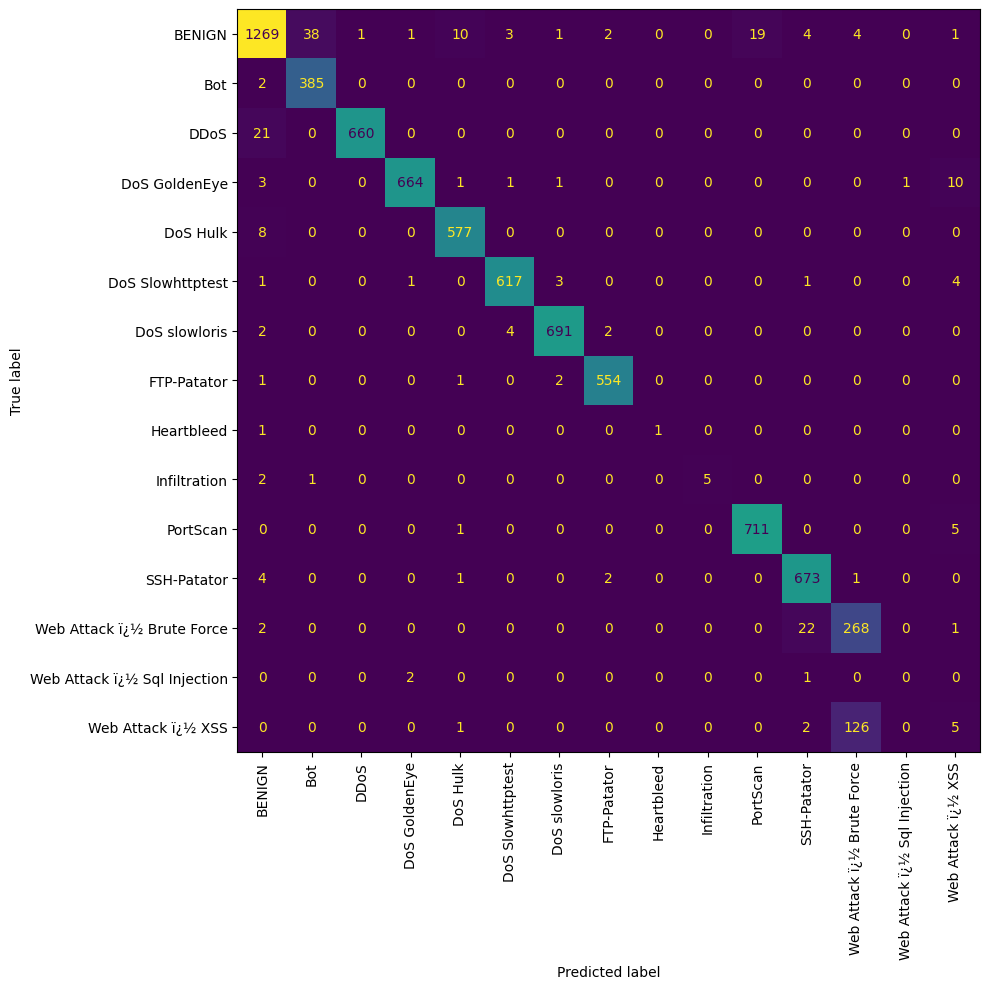

In [47]:
test_logits=restore_logits(selected_row,'test')
test_pred=pred_with_bias(test_logits,selection['bias'])
score=performance(y['test'],test_pred)
report=classification_report(y['test'],test_pred,labels=all_ids,target_names=classes,output_dict=True,zero_division=0)
per_class=pd.DataFrame(report).T.loc[classes].copy()
per_class.index.name='class_name'
per_class.to_csv(OUTPUT/'test_per_class_metrics.csv')
pd.DataFrame(report).T.to_csv(OUTPUT/'test_classification_report.csv')
cm=confusion_matrix(y['test'],test_pred,labels=all_ids)
pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUTPUT/'test_confusion_matrix_labeled.csv')
np.save(OUTPUT/'test_confusion_matrix.npy',cm)
rows=pd.DataFrame({'true_label':enc.inverse_transform(y['test']),'pred_label':enc.inverse_transform(test_pred)})
rows.to_csv(OUTPUT/'test_predictions.csv',index=False)
(rows[rows.true_label.ne(rows.pred_label)].groupby(['true_label','pred_label'])
 .size().reset_index(name='count').sort_values('count',ascending=False)
 .to_csv(OUTPUT/'test_confusion_pairs.csv',index=False))
final={'selected_method':chosen_method,'selected_seed':int(selection['seed']),
       'selected_bias':float(selection['bias']),'validation_score':{k:float(selection[k]) for k in ['macro_f1','accuracy','xss_recall','xss_f1','fpr']},
       'test':score,'split_sha256':sha,'protocol':'exploratory; exact-duplicate grouped split, not host/time independent',
       'warning':'Test already inspected in earlier versions; independent holdout required for final research claims'}
(OUTPUT/'final_test_metrics.json').write_text(json.dumps(final,indent=2,ensure_ascii=False))
shutil.copyfile(selected_row['checkpoint'],OUTPUT/'selected_best.pt')
print(json.dumps(final,indent=2,ensure_ascii=False))
display(per_class.sort_values('f1-score').round(4))
fig,ax=plt.subplots(figsize=(12,10))
ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=90,colorbar=False)
plt.tight_layout();fig.savefig(OUTPUT/'test_confusion_matrix.png',dpi=140);plt.show()


## 10. Đồ thị, audit và manifest

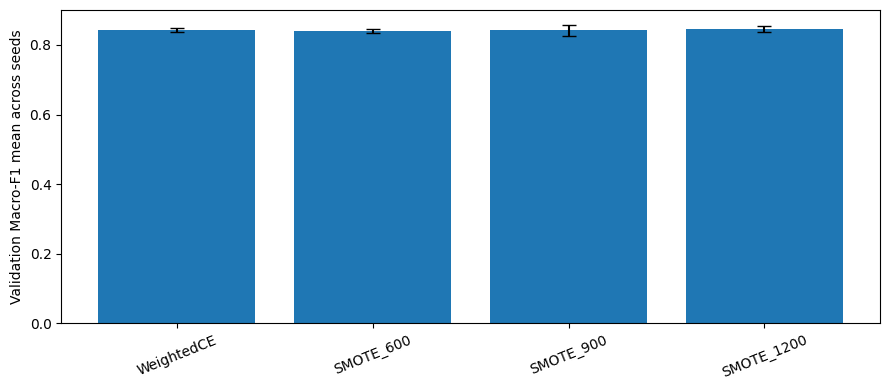

Saved: /kaggle/working/nids_outputs/05_V10_SMOTE_Stability files: 57


In [48]:
audit=trials[['strategy','seed','synthetic_count','xss_after']+[c for c in ('discrete_noninteger_fraction','discrete_outside_train_range_fraction') if c in trials.columns]].copy()
audit.to_csv(OUTPUT/'smote_quality_audit.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4))
agg=summary.set_index('strategy').loc[EXPERIMENTS]
ax.bar(agg.index,agg.macro_f1_mean,yerr=agg.macro_f1_std.fillna(0),capsize=5)
ax.set_ylabel('Validation Macro-F1 mean across seeds');ax.tick_params(axis='x',rotation=22)
plt.tight_layout();fig.savefig(OUTPUT/'method_stability.png',dpi=150);plt.show()
manifest_out={'experiment':'05_V10_SMOTE_Stability','arch':T4_ARCH,'source_03b_path':str(split_path),
              'split_sha256':sha,'feature_variant':feature_variant,'features':features,'classes':classes,
              'search_mode':SEARCH_MODE,'budget':BUDGET,'experiments':EXPERIMENTS,
              'smote_targets':SMOTE_TARGETS,'smote_k_neighbors':SMOTE_K_NEIGHBORS,
              'selection_rule':'method highest MEAN validation Macro-F1 over matched seeds, then best checkpoint and bias within method',
              'selected':selection,'caveats':['SMOTE applied only to train, only XSS',
              'Synthetic flows may be physically invalid','Test is reused exploratory pilot','Not host/time-disjoint']}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest_out,indent=2,ensure_ascii=False,default=str))
print('Saved:',OUTPUT,'files:',sum(p.is_file() for p in OUTPUT.rglob('*')))